### Supervised Learning Diagnostics
#### Lecture/Lab 24, Phys 4730 F26

<br>

Ref: V. Acquaviva, <i>Machine Learning for Physics and Astronomy</i> 

In [1]:
%reset -f

In [2]:
import pandas as pd
import numpy as np


import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

font = {'size'   : 14}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14) 
matplotlib.rc('ytick', labelsize=14) 
matplotlib.rcParams['figure.dpi'] = 100

import sklearn.tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics 
from sklearn.model_selection import cross_val_predict, cross_val_score, cross_validate
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn import tree
from sklearn.tree import export_graphviz
from scipy import stats

import pandas as pd
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)

### Read and tune the full HWC data set


In [3]:
### read the dataset ###

df = pd.read_csv('20240321_hwc_full.csv', sep = ',')

In [4]:
### Create a new data frame called bindf, dropping the ###
### old habitability label which had 3 possibilities.  ###
### Create instead a new habitability label which is   ###
### an OR of "optimistically habitable" and "expected  ###
### habitable". Recast the label as an integer.        ###

bindf = df.drop('P_HABITABLE', axis = 1) 
bindf['P_HABITABLE'] = (np.logical_or((df.P_HABITABLE == 1) , (df.P_HABITABLE == 2)))
bindf['P_HABITABLE'] = bindf['P_HABITABLE'].astype(int)

In [5]:
### Confine ourselves to 3(2) features and 1 target ###

NFEATURES = 2

if(NFEATURES == 3):
    final_features = bindf[['S_MASS', 'P_PERIOD', 'P_DISTANCE']]
else:
    final_features = bindf[['S_MASS', 'P_PERIOD']]
    
targets = bindf.P_HABITABLE   

In [6]:
### get rid of any instance with at least one NaN in any column ###

final_features = final_features.dropna(axis = 0) 

In [7]:
### Eliminates objects with > 5 sigma outliers in any column ###

final_features = final_features[(np.abs(stats.zscore(final_features)) < 5).all(axis=1)]

In [8]:
### keep only targets corresponding to final features we have chosen ###

targets = targets[final_features.index]

In [9]:
### reset the indices of the features and targets

final_features = final_features.reset_index(drop=True)
targets        = targets.reset_index(drop=True)

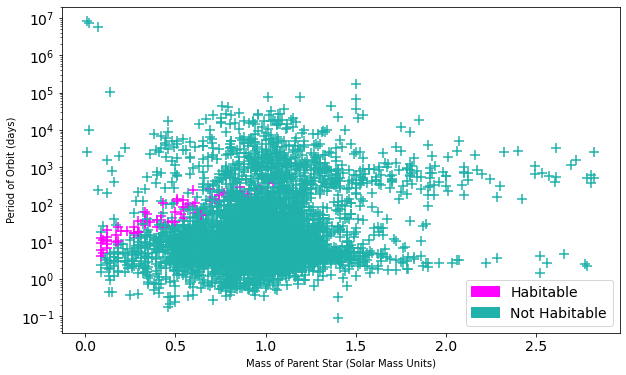

In [10]:
### make a feature-space scatter plot of our data, in the familiar form ###

plt.figure(figsize=(10,6))

cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ['#20B2AA','#FF00FF'])

a = plt.scatter(final_features['S_MASS'], final_features['P_PERIOD'], \
                marker = '+', c=targets, s = 100, cmap=cmap)

plt.yscale('log')
plt.xlabel('Mass of Parent Star (Solar Mass Units)')
plt.ylabel('Period of Orbit (days)');

bluepatch    = mpatches.Patch(color='#20B2AA', label='Not Habitable')
magentapatch = mpatches.Patch(color='#FF00FF', label='Habitable')

plt.legend(handles=[magentapatch, bluepatch], loc = 'lower right', fontsize = 14);

plt.show()

In [11]:
print("The fraction of positive targets is: %7.5f" % float(np.sum(targets)/len(targets)))
print("The number of positive targets is:   %5d"   % np.sum(targets))
print("The number of instances is:          %5d"   % len(targets))

The fraction of positive targets is: 0.01311
The number of positive targets is:      70
The number of instances is:           5339


### Now, do the decision tree training

In [12]:
### a random train/test split will assign 25% of instances to test set

Xtrain, Xtest, ytrain, ytest = train_test_split(final_features, targets, random_state=2)
Xtrain.shape, Xtest.shape

((4004, 2), (1335, 2))

In [13]:
### choose Decision Tree Method, build the model ###

model = DecisionTreeClassifier(random_state=5)
model.fit(Xtrain, ytrain)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,5
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [14]:
### check the accuracy scores ###

print("training set accuracy score:    %7.5f" % metrics.accuracy_score(ytrain, model.predict(Xtrain)))
print("testing set accuracy score:     %7.5f" % metrics.accuracy_score(ytest, model.predict(Xtest)))

training set accuracy score:    1.00000
testing set accuracy score:     0.99176


In [15]:
### sounds good, but suppose we had just classified everything as uninhabitable? ###

print("lazy classifier accuracy score: %7.5f" % metrics.accuracy_score(ytest, np.zeros(len(ytest))))

lazy classifier accuracy score: 0.98801


In [16]:
### check precision and recall scores ###

print("precision score: %7.5f" % metrics.precision_score(ytest,model.predict(Xtest)))
print("recall score:    %7.5f" % metrics.recall_score(ytest,model.predict(Xtest)))

precision score: 0.69231
recall score:    0.56250


In [17]:
### check confusion matrix ### 

cm = metrics.confusion_matrix(ytest,model.predict(Xtest))
print("confusion matrix: %10d  %10d" % (cm[0,0],cm[0,1])) 
print("                  %10d  %10d" % (cm[1,0],cm[1,1])) 

confusion matrix:       1315           4
                           7           9


### Now, let's look at k-fold Cross Validation.

In [18]:
### Version 1: Standard version. It doesn't shuffle the data,          ###
### so if your positive examples are all at the beginning or           ###
### all the end, it might lead to disastrous results.                  ### 

### Version 2: Adds shuffling (recommended!). Reqs random numbers.     ###

### Version 3: Stratification ensures that each split has the          ### 
### same distributions as the entire data set. Reqs random numbers.    ###

NS = 5

cv1 = KFold(n_splits = NS)

### Version 2: Adds shuffling (recommended!). Reqs random numbers.     ###

cv2 = KFold(shuffle = True, n_splits = NS, random_state=NS)

### Version 3: Stratification ensures that each split has the          ### 
### same distributions as the entire data set. Reqs random numbers.    ###

cv3 = StratifiedKFold(shuffle = True, n_splits = NS, random_state=NS)

In [19]:
### print out the class count for these splits ###

print("cv1 split:")
for train, test in cv1.split(final_features, targets):
    print('train -  {}   |   test -  {}'.format( \
    np.bincount(targets.loc[train]), np.bincount(targets.loc[test])))
print("")    
print("cv2 split:")
for train, test in cv2.split(final_features, targets):
    print('train -  {}   |   test -  {}'.format( \
    np.bincount(targets.loc[train]), np.bincount(targets.loc[test])))
print("")       
print("cv3 split:")
for train, test in cv3.split(final_features, targets):
    print('train -  {}   |   test -  {}'.format( \
    np.bincount(targets.loc[train]), np.bincount(targets.loc[test])))

cv1 split:
train -  [4212   59]   |   test -  [1057   11]
train -  [4216   55]   |   test -  [1053   15]
train -  [4220   51]   |   test -  [1049   19]
train -  [4218   53]   |   test -  [1051   17]
train -  [4210   62]   |   test -  [1059    8]

cv2 split:
train -  [4213   58]   |   test -  [1056   12]
train -  [4220   51]   |   test -  [1049   19]
train -  [4215   56]   |   test -  [1054   14]
train -  [4214   57]   |   test -  [1055   13]
train -  [4214   58]   |   test -  [1055   12]

cv3 split:
train -  [4215   56]   |   test -  [1054   14]
train -  [4215   56]   |   test -  [1054   14]
train -  [4215   56]   |   test -  [1054   14]
train -  [4215   56]   |   test -  [1054   14]
train -  [4216   56]   |   test -  [1053   14]


In [20]:
### CV1: use cross_validate function to find accuracy score ###

scores1 = cross_validate(DecisionTreeClassifier(), \
                         final_features, targets, cv = cv1, scoring = 'accuracy',
                         return_train_score = True)
scores1

{'fit_time': array([0.00347185, 0.00343657, 0.00309396, 0.00347114, 0.00301838]),
 'score_time': array([0.00122428, 0.00079751, 0.00080872, 0.00073338, 0.0007565 ]),
 'test_score': array([0.98970037, 0.98782772, 0.98501873, 0.97846442, 0.99062793]),
 'train_score': array([1., 1., 1., 1., 1.])}

In [21]:
### CV2: use cross_validate function to find accuracy score ###

scores2 = cross_validate(DecisionTreeClassifier(), \
                         final_features, targets, cv = cv2, scoring = 'accuracy',
                         return_train_score = True)
scores2

{'fit_time': array([0.00377417, 0.00344634, 0.00411415, 0.0034337 , 0.00334167]),
 'score_time': array([0.00086164, 0.00080132, 0.00093889, 0.00072932, 0.00072789]),
 'test_score': array([0.97940075, 0.98595506, 0.98970037, 0.9906367 , 0.98781631]),
 'train_score': array([1., 1., 1., 1., 1.])}

In [22]:
### CV3: use cross_validate function to find accuracy score ###

scores3 = cross_validate(DecisionTreeClassifier(), \
                         final_features, targets, cv = cv3, scoring = 'accuracy',
                         return_train_score = True)
scores3

{'fit_time': array([0.00319552, 0.0033555 , 0.00503469, 0.00305939, 0.00301504]),
 'score_time': array([0.00080991, 0.00115228, 0.00086379, 0.00072503, 0.00085616]),
 'test_score': array([0.98595506, 0.98876404, 0.98689139, 0.98782772, 0.97938144]),
 'train_score': array([1., 1., 1., 1., 1.])}

In [23]:
### compute average and standard deviation ###

print("cv1 split:")
print("The average accuracy is   {:.4f}".format(scores1['test_score'].mean()))
print("The standard deviation is {:.4f}".format(scores1['test_score'].std()))
print("")
print("cv2 split:")
print("The average accuracy is   {:.4f}".format(scores2['test_score'].mean()))
print("The standard deviation is {:.4f}".format(scores2['test_score'].std()))
print("")
print("cv3 split:")
print("The average accuracy is   {:.4f}".format(scores3['test_score'].mean()))
print("The standard deviation is {:.4f}".format(scores3['test_score'].std()))
print("")

cv1 split:
The average accuracy is   0.9863
The standard deviation is 0.0044

cv2 split:
The average accuracy is   0.9867
The standard deviation is 0.0040

cv3 split:
The average accuracy is   0.9858
The standard deviation is 0.0033



In [24]:
### CV1: use cross_validate function to find recall score ###

scores1 = cross_validate(DecisionTreeClassifier(random_state=1), \
                         final_features, targets, cv = cv1, scoring = 'recall',
                         return_train_score = True)
scores1

{'fit_time': array([0.00411844, 0.00369835, 0.00333095, 0.00354314, 0.00311351]),
 'score_time': array([0.00259423, 0.00149131, 0.00142145, 0.00139689, 0.00140333]),
 'test_score': array([0.63636364, 0.46666667, 0.42105263, 0.35294118, 0.875     ]),
 'train_score': array([1., 1., 1., 1., 1.])}

In [25]:
### CV2: use cross_validate function to find recall score ###

scores2 = cross_validate(DecisionTreeClassifier(random_state=1), \
                         final_features, targets, cv = cv2, scoring = 'recall',
                         return_train_score = True)
scores2

{'fit_time': array([0.00376034, 0.00426078, 0.0036211 , 0.00345683, 0.00355721]),
 'score_time': array([0.00173545, 0.00175905, 0.00143385, 0.00140285, 0.00142026]),
 'test_score': array([0.33333333, 0.42105263, 0.5       , 0.61538462, 0.33333333]),
 'train_score': array([1., 1., 1., 1., 1.])}

In [26]:
### CV3: use cross_validate function to find recall score ###

scores3 = cross_validate(DecisionTreeClassifier(random_state=1), \
                         final_features, targets, cv = cv3, scoring = 'recall',
                         return_train_score = True)
scores3

{'fit_time': array([0.00334072, 0.00358891, 0.00358462, 0.00323939, 0.00322795]),
 'score_time': array([0.00157332, 0.00140285, 0.00136781, 0.00155711, 0.00139499]),
 'test_score': array([0.42857143, 0.57142857, 0.35714286, 0.64285714, 0.5       ]),
 'train_score': array([1., 1., 1., 1., 1.])}

In [27]:
### compute average and standard deviation ###

print("cv1 split:")
print("The average recall is     {:.4f}".format(scores1['test_score'].mean()))
print("The standard deviation is {:.4f}".format(scores1['test_score'].std()))
print("")
print("cv2 split:")
print("The average recall is     {:.4f}".format(scores2['test_score'].mean()))
print("The standard deviation is {:.4f}".format(scores2['test_score'].std()))
print("")
print("cv3 split:")
print("The average recall is     {:.4f}".format(scores3['test_score'].mean()))
print("The standard deviation is {:.4f}".format(scores3['test_score'].std()))
print("")

cv1 split:
The average recall is     0.5504
The standard deviation is 0.1873

cv2 split:
The average recall is     0.4406
The standard deviation is 0.1072

cv3 split:
The average recall is     0.5000
The standard deviation is 0.1010



In [28]:
### to get the confusion matrix, we need the predicted labels ###

model1 = DecisionTreeClassifier(random_state = 3)
y1     = cross_val_predict(model1, final_features, targets, cv = cv1) 

model2 = DecisionTreeClassifier(random_state = 3)
y2     = cross_val_predict(model2, final_features, targets, cv = cv2) 

model3 = DecisionTreeClassifier(random_state = 3)
y3     = cross_val_predict(model3, final_features, targets, cv = cv3) 


cm = metrics.confusion_matrix(targets,y1)
print("cv1 split:")
print("confusion matrix: %10d  %10d" % (cm[0,0],cm[0,1])) 
print("                  %10d  %10d" % (cm[1,0],cm[1,1])) 
print("")

cm = metrics.confusion_matrix(targets,y2)
print("cv2 split:")
print("confusion matrix: %10d  %10d" % (cm[0,0],cm[0,1])) 
print("                  %10d  %10d" % (cm[1,0],cm[1,1])) 
print("")

cm = metrics.confusion_matrix(targets,y3)
print("cv3 split:")
print("confusion matrix: %10d  %10d" % (cm[0,0],cm[0,1])) 
print("                  %10d  %10d" % (cm[1,0],cm[1,1])) 
print("")

cv1 split:
confusion matrix:       5233          36
                          36          34

cv2 split:
confusion matrix:       5237          32
                          39          31

cv3 split:
confusion matrix:       5232          37
                          37          33



### Finally, plot learning curves

A detailed description of the <b>learning_curve</b> function can be found [here](https://scikit-learn.org/stable/auto_examples/model_selection/plot_learning_curve.html).

Basically, we want to see how the scores vary with data set size. 

In [29]:
from sklearn.model_selection import learning_curve

def plot_learning_curve(estimator, title, X, y, ylim=None, cv=5, n_jobs=-1, \
                        train_sizes=np.linspace(.1, 1.0, 5), scoring = 'accuracy'):
    
    plt.figure(figsize=(10,6))
    plt.title(title)
    if ylim is not None:
        plt.ylim(*ylim)
    plt.xlabel("Training examples")
    plt.ylabel(str(scoring))
    
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=cv, n_jobs=n_jobs, train_sizes=train_sizes, scoring = scoring)
    
    train_scores_mean = np.mean(train_scores, axis=1)
    train_scores_std  = np.std(train_scores, axis=1)
    test_scores_mean  = np.mean(test_scores, axis=1)
    test_scores_std   = np.std(test_scores, axis=1)
    plt.grid()

    plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                     train_scores_mean + train_scores_std, alpha=0.1,
                     color="r")

    plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                     test_scores_mean + test_scores_std, alpha=0.1, color="g")

    plt.plot(train_sizes, train_scores_mean, 'o-', color="r",
             label="Training score")

    plt.plot(train_sizes, test_scores_mean,  'o-', color="g",
             label="Test score from cross-validation")

    plt.legend(loc="best")
    return plt

In [30]:
model = DecisionTreeClassifier(random_state = 5)

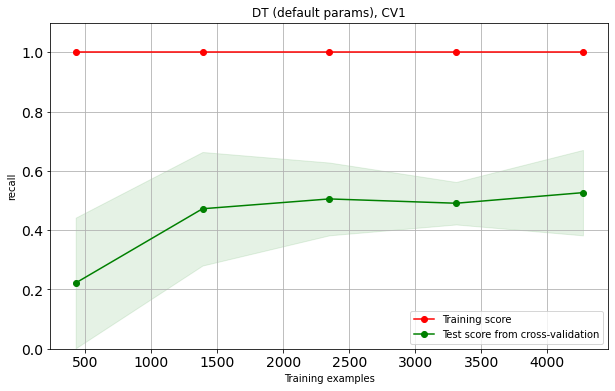

In [31]:
plot_learning_curve(model,'DT (default params), CV1', final_features, targets, [0.0,1.1], \
                    cv = cv1, scoring = 'recall');

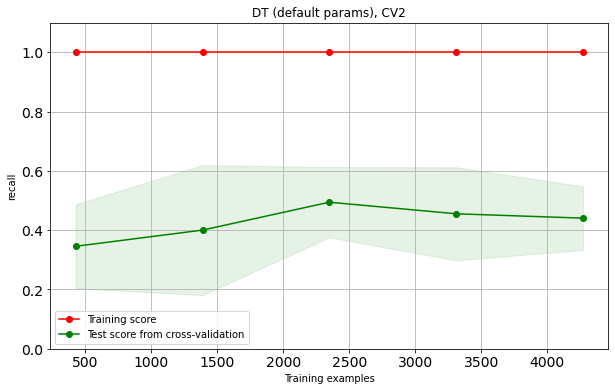

In [32]:
plot_learning_curve(model,'DT (default params), CV2', final_features, targets, [0.0,1.1], \
                    cv = cv2, scoring = 'recall');

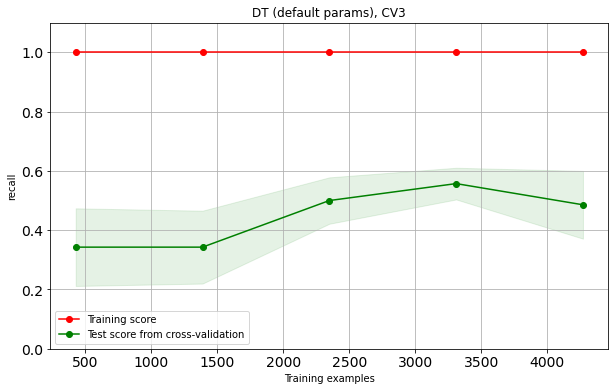

In [33]:
plot_learning_curve(model,'DT (default params), CV3', final_features, targets, [0.0,1.1], \
                    cv = cv3, scoring = 'recall');

### Please answer the following questions:

* If the accuracy score is 100%, what will be the precision and recall scores?

<font color="#ff0000"> If the accuracy score is 100%, it means the confusion matrix is diagonal. In this case, both precision and recall scores will be 100% as well. </font>

* What is the effect of shuffling and stratification on the k-fold splits?

<font color="#ff0000"> Test sets have more evenly distributed numbers of positive labels in
   the shuffled sets, and identical ones in the stratified sets. </font>

* Within the particular k-fold schemes, are the differences in scores statistically significant for any of the splits? Explain.

<font color="#ff0000"> Have a look at the figures below, which compare first the splits within the CV methods and then the methods themselves. All seem similar, at this level of statistics. </font>

* Does the confusion matrix depend on the cross-validation scheme chosen? Why or why not?

<font color="#ff0000"> Yes. The tree and CM are made with the use of random numbers, and the different datasets will be expected to produce (hopefully, slightly!) different outcomes. </font>

* Do the learning curves exhibit any significant differences for the three cross-validation schemes?

<font color="#ff0000"> See the figures above. Differences do not appear to be significant, at this level. </font>


In [34]:
### summary of cross-validation data ###

cv1acc = np.array([0.98876404, 0.98970037, 0.9840824 , 0.97940075, 0.99437676])
cv2acc = np.array([0.98033708, 0.98595506, 0.98970037, 0.99157303, 0.9868791 ])
cv3acc = np.array([0.98595506, 0.98876404, 0.98689139, 0.98782772, 0.97938144])

cv1rec = np.array([0.63636364, 0.46666667, 0.42105263, 0.35294118, 0.875     ])
cv2rec = np.array([0.33333333, 0.42105263, 0.5       , 0.61538462, 0.33333333])
cv3rec = np.array([0.42857143, 0.57142857, 0.35714286, 0.64285714, 0.5       ])

testno = np.array([1.0, 2.0, 3.0, 4.0, 5.0 ])

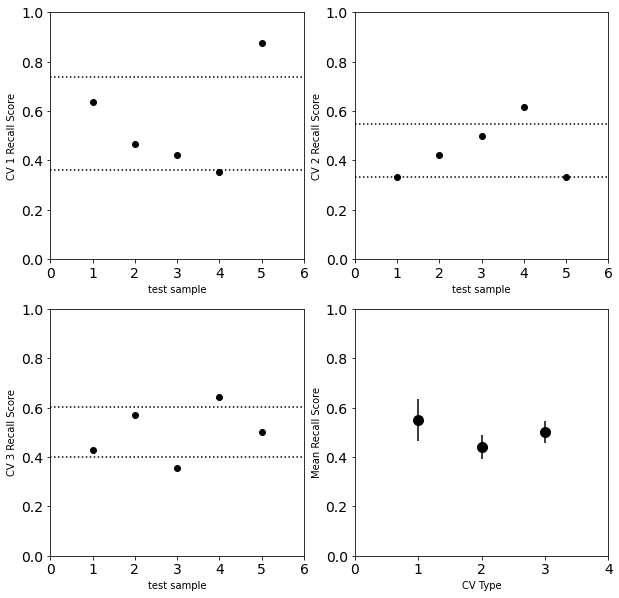

In [35]:
### plots to check consistency ###

plt.figure(figsize=(10,10))

### Cross-Validation 1 Split Comparison ###

plt.subplot(221)

cv1avg = np.average(cv1rec)
cv1sig = np.std(cv1rec)

tmin = 0.0
tmax = 6.0

plt.scatter(testno,cv1rec,c='k')
plt.plot([tmin,tmax],[cv1avg+cv1sig,cv1avg+cv1sig],linestyle="dotted",c='k')
plt.plot([tmin,tmax],[cv1avg-cv1sig,cv1avg-cv1sig],linestyle="dotted",c='k')
plt.axis([tmin,tmax,0.0,1.0])
plt.xlabel("test sample")
plt.ylabel("CV 1 Recall Score")

### Cross-Validation 2 Split Comparison ###

plt.subplot(222)

cv2avg = np.average(cv2rec)
cv2sig = np.std(cv2rec)

tmin = 0.0
tmax = 6.0

plt.scatter(testno,cv2rec,c='k')
plt.plot([tmin,tmax],[cv2avg+cv2sig,cv2avg+cv2sig],linestyle="dotted",c='k')
plt.plot([tmin,tmax],[cv2avg-cv2sig,cv2avg-cv2sig],linestyle="dotted",c='k')
plt.axis([tmin,tmax,0.0,1.0])
plt.xlabel("test sample")
plt.ylabel("CV 2 Recall Score")

### Cross-Validation 3 Split Comparison ###

plt.subplot(223)

cv3avg = np.average(cv3rec)
cv3sig = np.std(cv3rec)

tmin = 0.0
tmax = 6.0

plt.scatter(testno,cv3rec,c='k')
plt.plot([tmin,tmax],[cv3avg+cv3sig,cv3avg+cv3sig],linestyle="dotted",c='k')
plt.plot([tmin,tmax],[cv3avg-cv3sig,cv3avg-cv3sig],linestyle="dotted",c='k')
plt.axis([tmin,tmax,0.0,1.0])
plt.xlabel("test sample")
plt.ylabel("CV 3 Recall Score")

### look at means and errors of the three CV methods ###

plt.subplot(224)

tmin = 0.0
tmax = 4.0

plt.errorbar([1.0,2.0,3.0],[cv1avg,cv2avg,cv3avg],\
             [cv1sig/np.sqrt(5),cv2sig/np.sqrt(5),cv3sig/np.sqrt(5)],\
             linestyle='',marker='o',markersize=10.0,c='k')

plt.axis([tmin,tmax,0.0,1.0])
plt.xlabel("CV Type")
plt.ylabel("Mean Recall Score")

plt.show()